# Run transfert-learning

Commandes adaptées à la structure actuelle du dépôt. Les sorties enregistrées proviennent des exécutions initiales.

In [ ]:
!nvidia-smi

Thu Oct 22 10:45:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

%cd /content
!rm -rf OpenVaccine
!git clone https://github.com/elifmgungor/OpenVaccine.git OpenVaccine
%cd /content/OpenVaccine

!mkdir -p data
!unzip -q -o /content/drive/MyDrive/openvaccine_data.zip -d data/
DRIVE_OUT = "/content/drive/MyDrive/openvaccine_outputs"
!if [ -d outputs ] && [ ! -L outputs ]; then cp -rn outputs/. {DRIVE_OUT}/ && rm -rf outputs; fi
!ln -sfn {DRIVE_OUT} outputs

%env TF_CPP_MIN_LOG_LEVEL=2
!ls outputs/

Mounted at /content/drive
/content
Cloning into 'OpenVaccine'...
remote: Enumerating objects: 114, done.
remote: Counting objects: 100% (114/114), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 114 (delta 30), reused 101 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (114/114), 1.78 MiB | 8.92 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/OpenVaccine
env: TF_CPP_MIN_LOG_LEVEL=2
mean	      rnafm	      tl     tl_50	   tl_rnafm    tl_scratch_25
mlm_pretrain  test_drive.txt  tl_25  tl_mlm_rnafm  tl_scratch  tl_scratch_50


In [2]:
%cd /content/OpenVaccine
DRIVE_OUT = "/content/drive/MyDrive/openvaccine_outputs"
!mkdir -p {DRIVE_OUT}
!rm -rf outputs && ln -sfn {DRIVE_OUT} outputs
!touch outputs/test_drive.txt
!ls -la outputs && ls /content/drive/MyDrive/openvaccine_outputs

/content/OpenVaccine
lrwxrwxrwx 1 root root 42 Oct 22 12:30 outputs -> /content/drive/MyDrive/openvaccine_outputs
mean	      rnafm	      tl     tl_50	   tl_rnafm    tl_scratch_25
mlm_pretrain  test_drive.txt  tl_25  tl_mlm_rnafm  tl_scratch  tl_scratch_50


In [ ]:
!pip -q install -r requirements-transfer.txt
!python -c "import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')"

True Tesla T4


## Test

In [ ]:
!python -m tests.smoke_transfer


[1] Imports et dépendances
I0000 00:00:1792571157.161554    3794 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
    OK  python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | torch 2.11.0+cu130 | keras 3.13.2 (backend tensorflow)
    OK  device : cuda

[2] Données prétraitées
    OK  train.npz : 2400 molécules ; sous-ensemble de test : 32
    OK  shapes : tokens (32, 107, 3), feats (32, 107, 4), bpps (32, 107, 107), pairs (32, 107), targets (32, 68, 5)

[3] Batching (longueur homogène, conversion torch)
    OK  batch : tokens (8, 107, 3) torch.int32, feats torch.float32

[4] Masquage MLM (proportions et absence de fuite)
    OK  14.7% des bases masquées ; adjacence et feats effacées aux positions masquées

[5] Encodeur complet : forward sur 107 et 130 nt
    OK  2.02 M paramètres ; sorties finies pour les deux longueurs

[6] Pré-entraînement : sur-apprentissage d'un batch (la loss doit chuter)
    OK  loss MLM 3.142 -> 0.018

[7] Sauvegarde / chargement d

## Pre-training on one poch to see the time

In [ ]:
%%time
!python -m experiments.transfer.pretrain --epochs 1 --out outputs/mlm_pretrain/smoke.pt

MLM : 5733 molécules train, 301 validation
[MLM] ep   0  loss 1.4649  val_loss 1.2046  masked_nt_acc 0.592
-> outputs/mlm_pretrain/smoke.pt
CPU times: user 21.4 ms, sys: 5.7 ms, total: 27.1 ms
Wall time: 11.5 s


## Small fine-tuning, abalation and reference

In [ ]:
%%time
!python -m experiments.transfer.finetune --only-fold 0 --epochs 2 --ckpt outputs/mlm_pretrain/smoke.pt --name tl_smoke
!python -m experiments.transfer.finetune --only-fold 0 --epochs 2 --ckpt none --name tl_scratch_smoke
!python -m experiments.from_scratch.train --model mean --only-fold 0 --name mean_smoke

I0000 00:00:1792571189.131352    3951 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

===== tl_smoke | fold 0 =====
ep   0  loss 0.4638  val_loss 0.4023  val_mcrmse 0.4199
ep   1  loss 0.3865  val_loss 0.3692  val_mcrmse 0.3844
fold 0 MCRMSE = 0.3844
{
  "cv_mcrmse": 0.3844284117221832,
  "cv_mcrmse_5targets": 0.36920613050460815,
  "fold_mcrmse": {
    "0": 0.3844284117221832
  },
  "rmse_per_target": {
    "reactivity": 0.33489999175071716,
    "deg_Mg_pH10": 0.4381999969482422,
    "deg_pH10": 0.37139999866485596,
    "deg_Mg_50C": 0.38019999861717224,
    "deg_50C": 0.3212999999523163
  },
  "args": {
    "name": "tl_smoke",
    "folds": "kfold",
    "only_fold": 0,
    "lr": 0.001,
    "batch_size": 64,
    "epochs": 2,
    "patience": 10,
    "all_samples": false,
    "ckpt": "outputs/mlm_pretrain/smoke.pt",
    "lr_enc": 0.0001,
    "freeze_epochs": 3,
    "label_frac": 1.0,
    "sn_weight": false
  }
}
-> /content/OpenVaccine/outputs/tl_sm

In [ ]:
!python -c "import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')"

True Tesla T4


In [ ]:
!ls outputs/tl_smoke
!python -c "import numpy as np, pandas as pd; o=np.load('outputs/tl_smoke/oof.npy'); s=pd.read_csv('outputs/tl_smoke/submission.csv'); print('oof', o.shape, '| prédites :', (~np.isnan(o).any(axis=(1,2))).sum(), '| submission', s.shape, '| NaN :', int(s.isna().sum().sum()))"
!python -m experiments.transfer.compare --runs tl_smoke tl_scratch_smoke mean_smoke --folds kfold
!python -m scripts.ensemble --runs tl_smoke tl_scratch_smoke mean_smoke --name ensemble_smoke

history_fold0.csv  model_fold0.pt  oof.npy  scores.json  submission.csv
oof (2400, 68, 5) | prédites : 480 | submission (457953, 6) | NaN : 0
318 molécules utilisées pour l'évaluation

=== Tableau principal ===
| run              |   MCRMSE (officielle, 3 cibles) | par fold (moy ± std)   |   MCRMSE 5 cibles |   reactivity |   deg_Mg_pH10 |   deg_pH10 |   deg_Mg_50C |   deg_50C |
|:-----------------|--------------------------------:|:-----------------------|------------------:|-------------:|--------------:|-----------:|-------------:|----------:|
| tl_scratch_smoke |                          0.3208 | 0.3208 ± 0.0000        |            0.3135 |       0.2805 |        0.3661 |     0.3271 |       0.3157 |    0.2784 |
| tl_smoke         |                          0.3844 | 0.3844 ± 0.0000        |            0.3692 |       0.3349 |        0.4382 |     0.3714 |       0.3802 |    0.3213 |
| mean_smoke       |                          0.4283 | 0.4283 ± 0.0000        |            0.4054 |      

In [ ]:
!rm -rf outputs/*smoke* outputs/mlm_pretrain/smoke.pt


## True runs

In [ ]:
%env TF_CPP_MIN_LOG_LEVEL=2
!python -c "import torch, keras, numpy, pandas, scipy, sklearn, tabulate; print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '| keras', keras.__version__, keras.backend.backend())"
import os, subprocess

def done(name):
    return os.path.exists(f"outputs/{name}/scores.json")

if not os.path.exists("outputs/mlm_pretrain/encoder.pt"):
    !python -m experiments.transfer.pretrain --epochs 100

runs = [
    ("mean",          "python -m experiments.from_scratch.train --model mean"),
    ("tl",            "python -m experiments.transfer.finetune"),
    ("tl_scratch",    "python -m experiments.transfer.finetune --ckpt none"),
    ("tl_25",         "python -m experiments.transfer.finetune --label-frac 0.25 --name tl_25"),
    ("tl_scratch_25", "python -m experiments.transfer.finetune --label-frac 0.25 --ckpt none --name tl_scratch_25"),
    ("tl_50",         "python -m experiments.transfer.finetune --label-frac 0.5 --name tl_50"),
    ("tl_scratch_50", "python -m experiments.transfer.finetune --label-frac 0.5 --ckpt none --name tl_scratch_50"),
]
for name, cmd in runs:
    if done(name):
        print(f"{name} : déjà fait")
        continue
    print(f"===== {name} =====")
    subprocess.run(cmd, shell=True, check=True)

env: TF_CPP_MIN_LOG_LEVEL=2
I0000 00:00:1792657986.248537    7547 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
torch 2.11.0+cu130 | CUDA True | keras 3.13.2 tensorflow
mean : déjà fait
===== tl =====
===== tl_scratch =====
===== tl_25 =====
===== tl_scratch_25 =====
===== tl_50 =====
===== tl_scratch_50 =====


In [ ]:
!tail -2 outputs/mlm_pretrain/history.csv
!ls outputs/

98,0.24533190799283458,0.2662483975291252,0.9046015712682379
99,0.24631593924957318,0.2662481938799222,0.9046015712682379
mean	      test_drive.txt  tl_25  tl_scratch     tl_scratch_50
mlm_pretrain  tl	      tl_50  tl_scratch_25


In [ ]:
!python -m experiments.transfer.compare --runs tl_25 tl_scratch_25 --folds kfold
!python -m experiments.transfer.compare --runs tl_50 tl_scratch_50 --folds kfold
!python -m experiments.transfer.compare --runs tl tl_scratch mean --folds kfold
!python -m experiments.transfer.figures

1589 molécules utilisées pour l'évaluation

=== Tableau principal ===
| run           |   MCRMSE (officielle, 3 cibles) | par fold (moy ± std)   |   MCRMSE 5 cibles |   reactivity |   deg_Mg_pH10 |   deg_pH10 |   deg_Mg_50C |   deg_50C |
|:--------------|--------------------------------:|:-----------------------|------------------:|-------------:|--------------:|-----------:|-------------:|----------:|
| tl_25         |                          0.2925 | 0.2923 ± 0.0085        |            0.2870 |       0.2538 |        0.3352 |     0.2983 |       0.2883 |    0.2595 |
| tl_scratch_25 |                          0.2943 | 0.2942 ± 0.0061        |            0.2889 |       0.2581 |        0.3354 |     0.3010 |       0.2894 |    0.2608 |

=== Bootstrap apparié, MCRMSE officielle (Δ = A − B ; négatif = A meilleur) ===
tl_25 vs tl_scratch_25 : Δ=-0.0018  IC95 [-0.0041, +0.0006]  P(Δ≥0)=0.065

=== RMSE par type de boucle : tl_25 ===
| loop   |   n_pos |   reactivity |   deg_Mg_pH10 |   deg_pH10

report/figures/fig_learning_curves.png


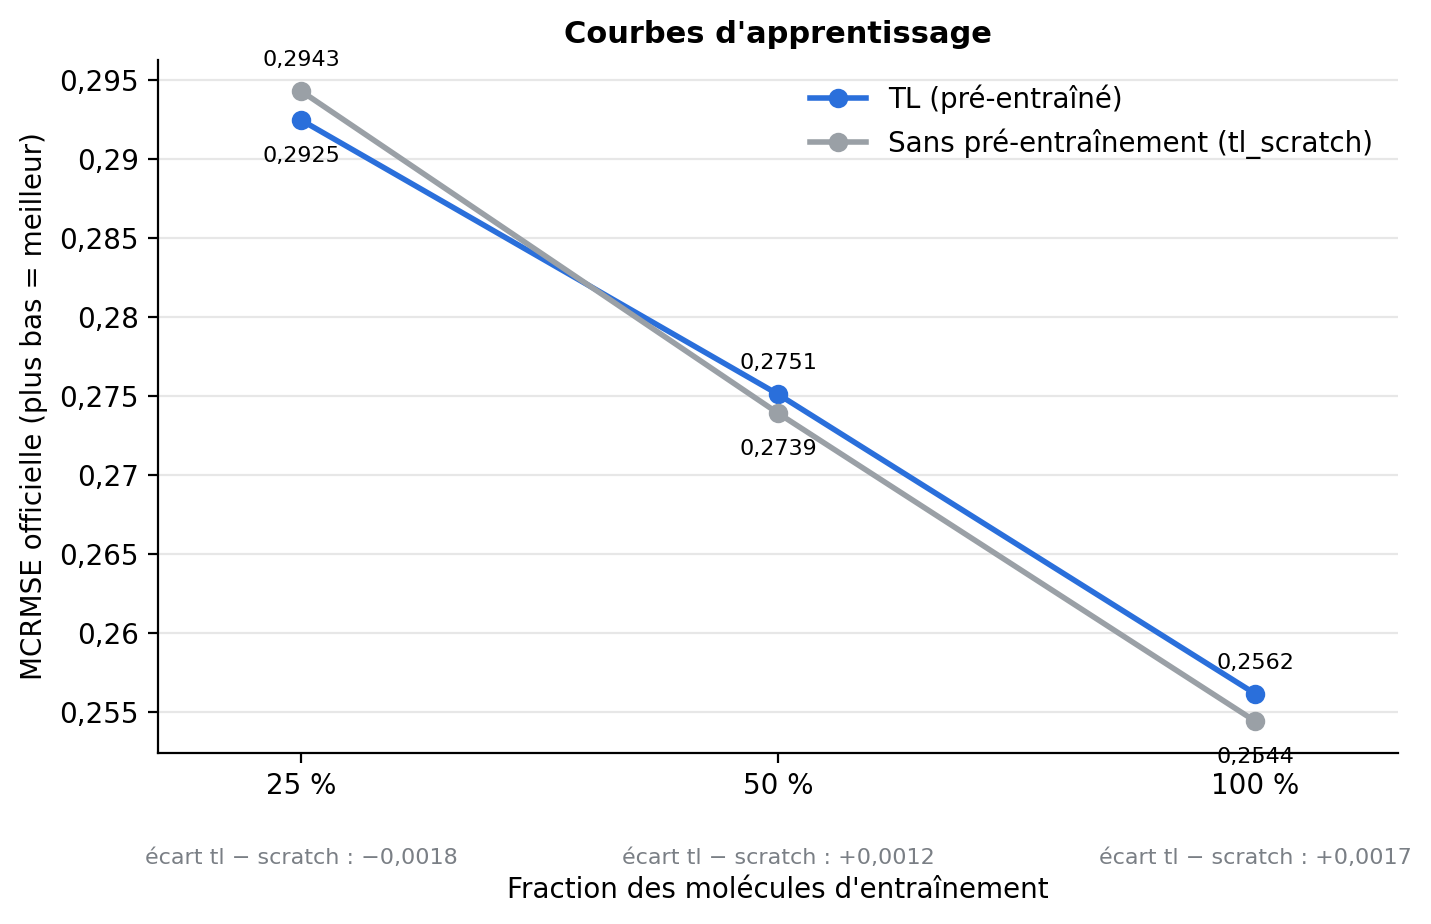

report/figures/fig_loop_diff.png


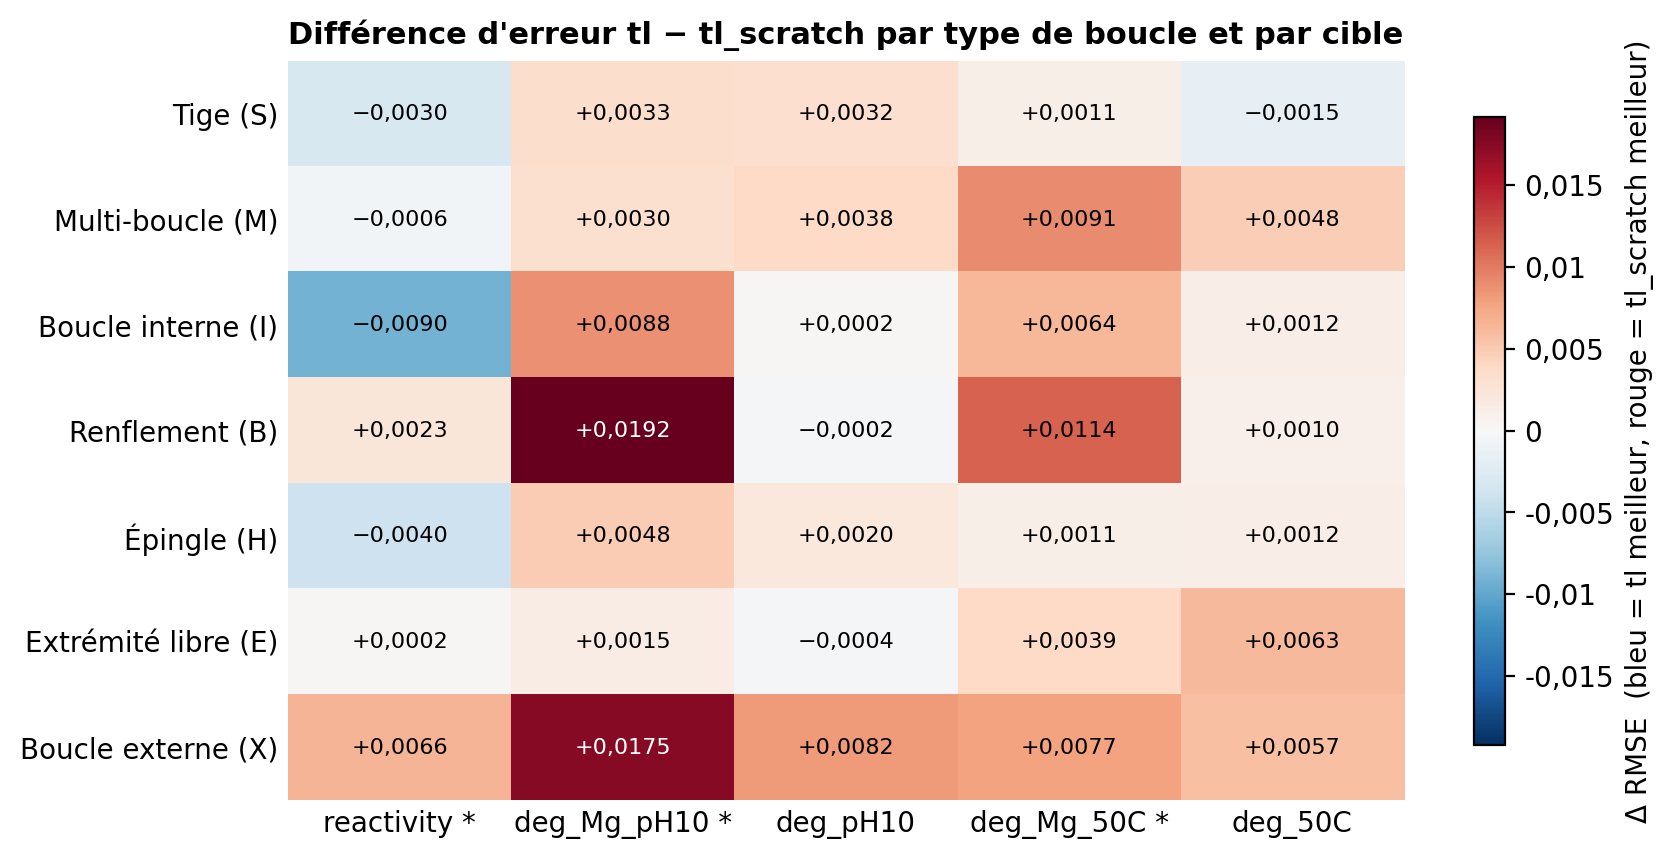

report/figures/fig_loop_gain.png


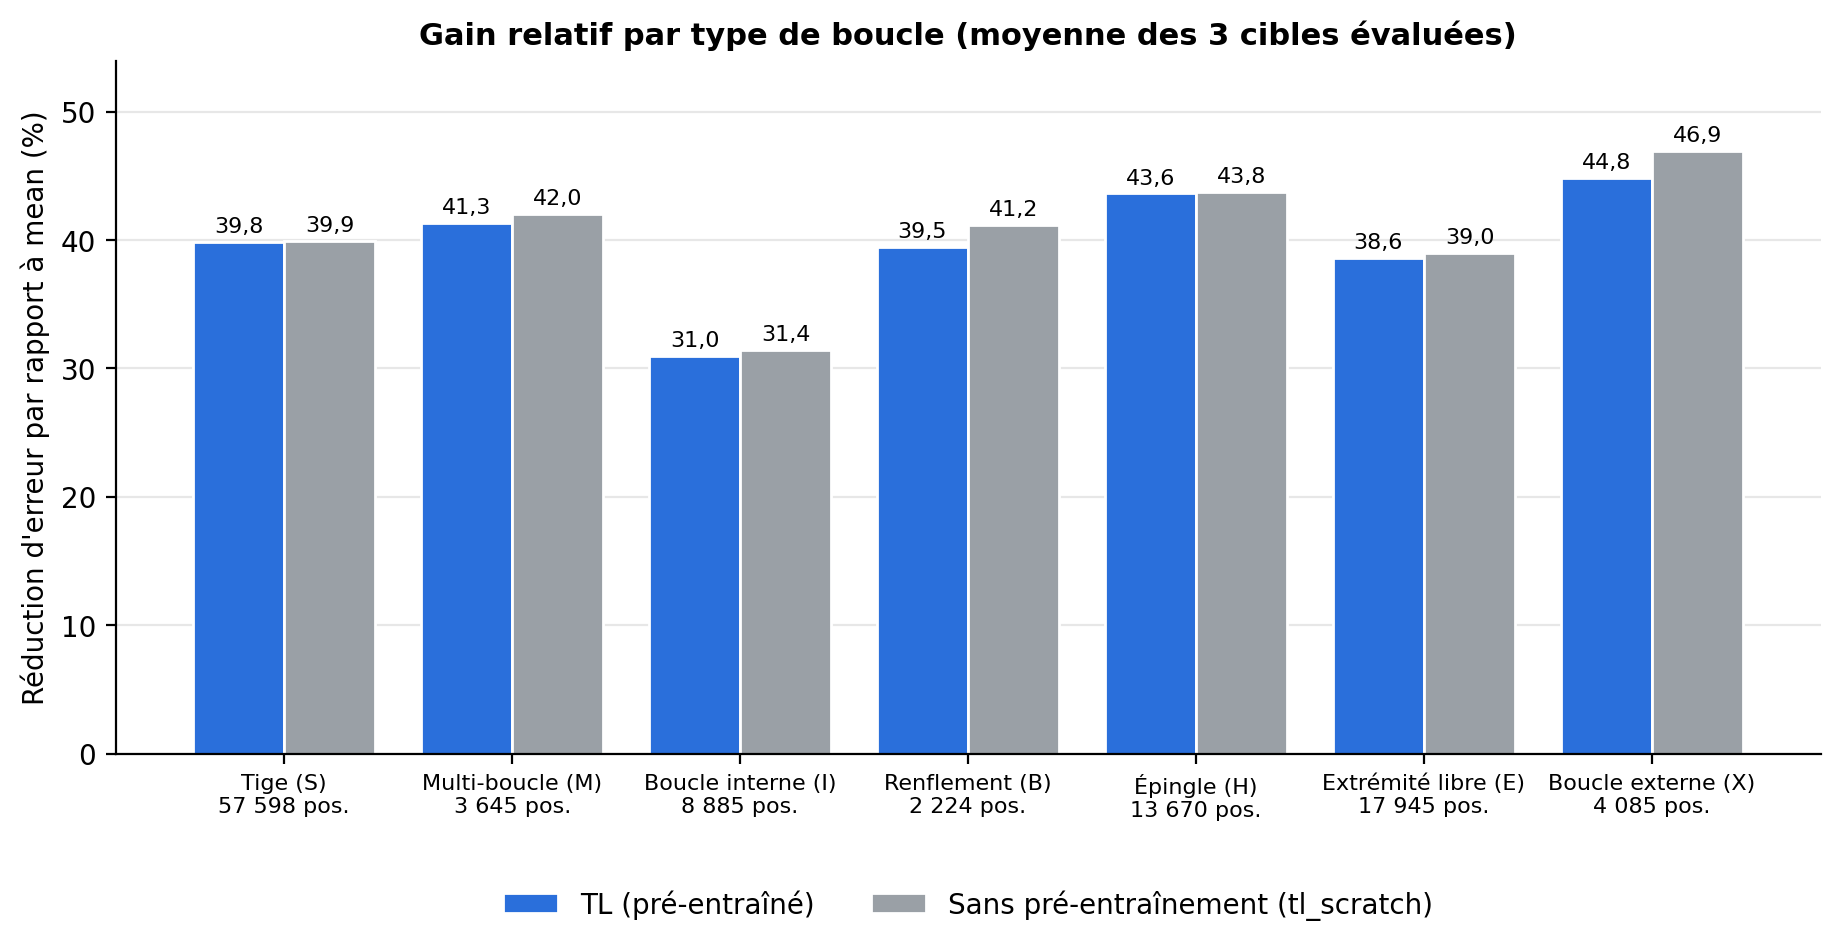

report/figures/fig_pretraining.png


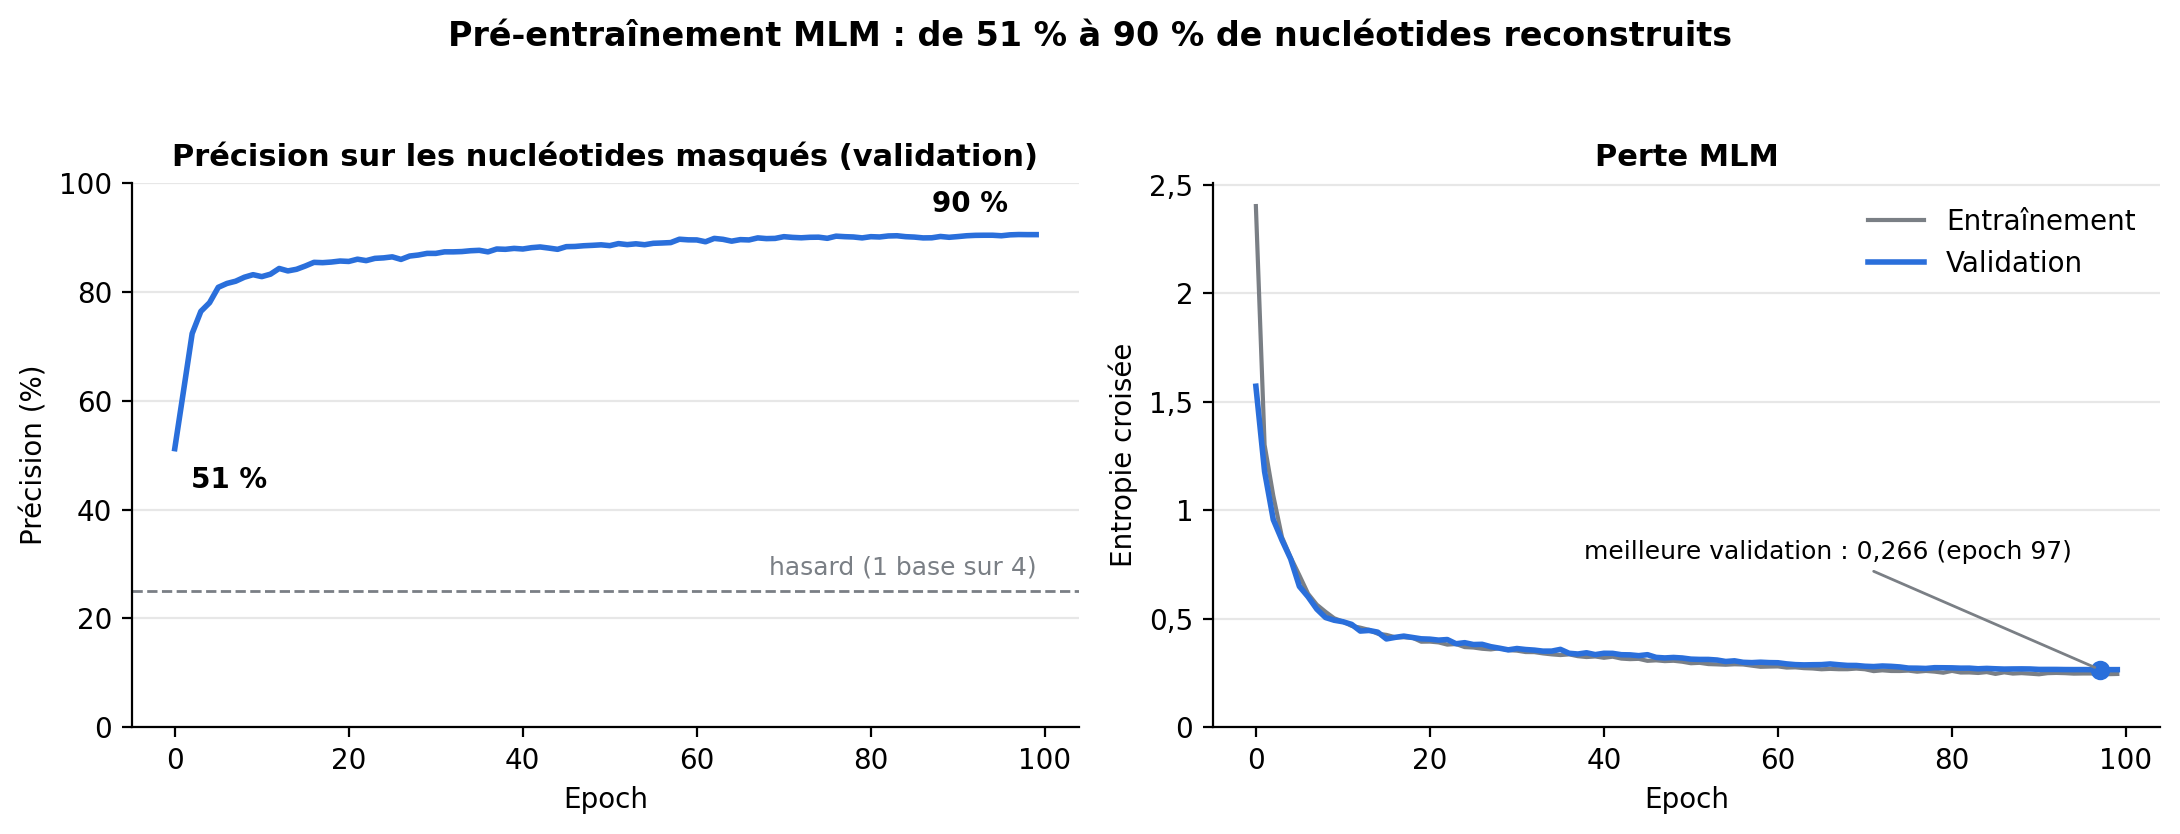

report/figures/fig_targets.png


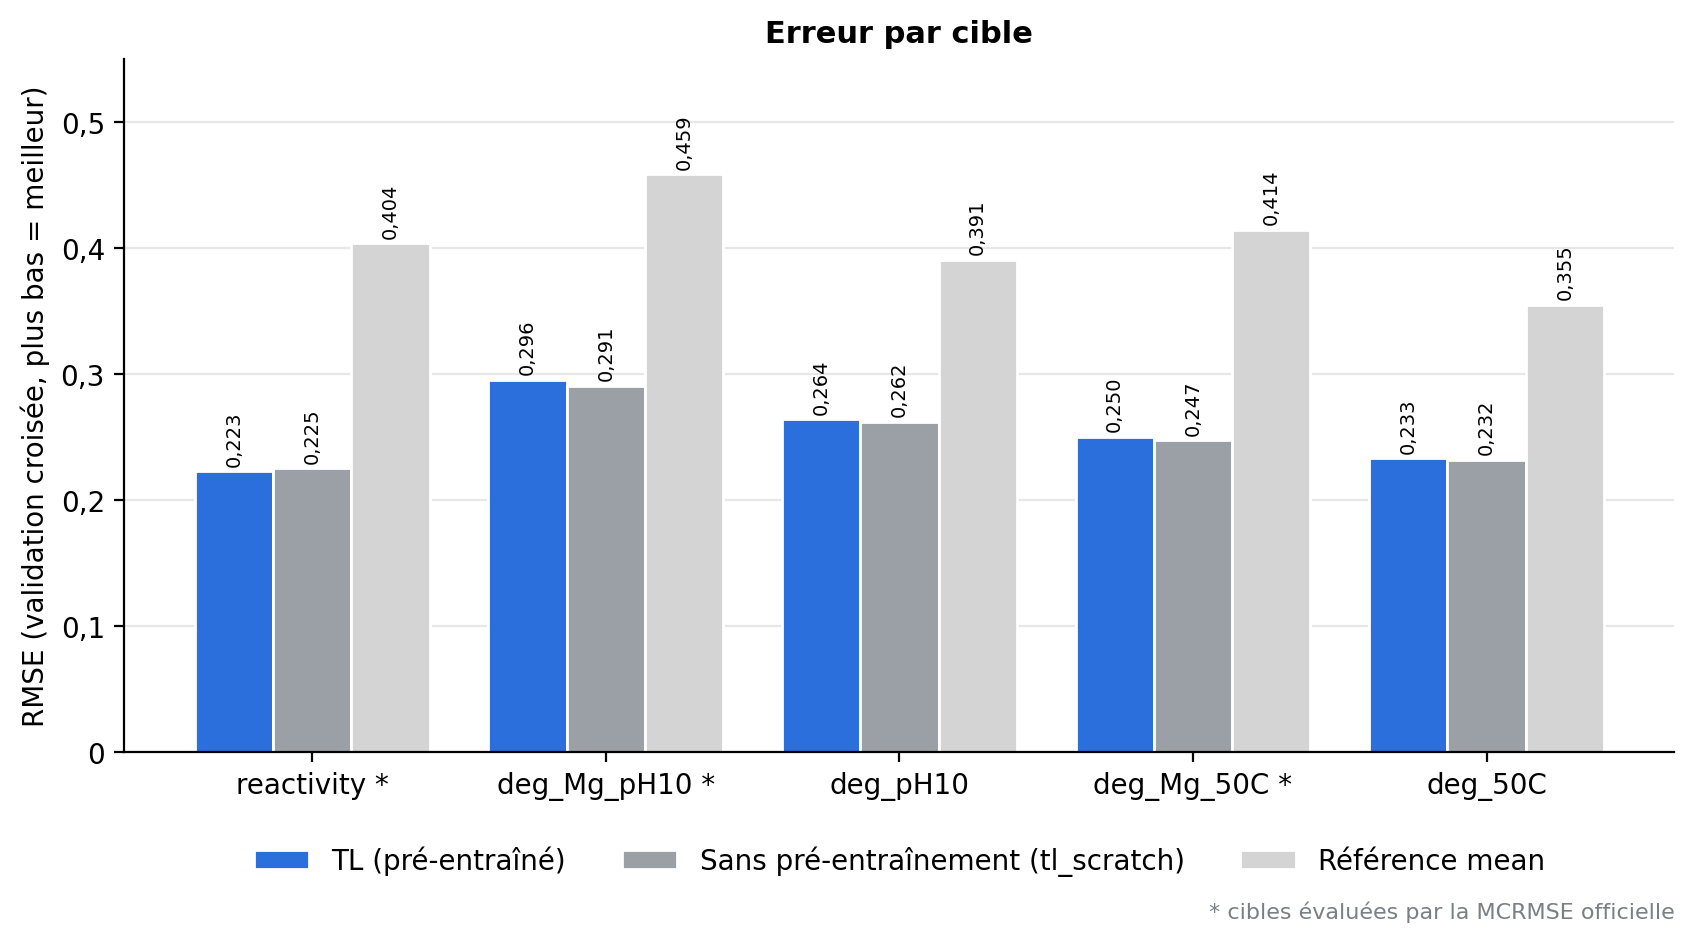

In [ ]:
from IPython.display import Image, display
import glob

for f in sorted(glob.glob("figures/transfer/*.png")):
    print(f)
    display(Image(f, width=900))

In [ ]:
!mkdir -p /content/drive/MyDrive/openvaccine_report/figures /content/drive/MyDrive/openvaccine_report/tables
!cp -r figures/transfer/. /content/drive/MyDrive/openvaccine_report/figures/
!cp -r results/transfer/. /content/drive/MyDrive/openvaccine_report/tables/
!ls /content/drive/MyDrive/openvaccine_report/figures/


fig_learning_curves.png  fig_loop_gain.png    fig_targets.png
fig_loop_diff.png	 fig_pretraining.png


## RNA-FM

In [ ]:
!ls extract_rnafm.py
!grep -c "rnafm" train_tl.py src/transfer/finetune.py

extract_rnafm.py
train_tl.py:4
src/transfer/finetune.py:10


In [ ]:
!pip install -q rna-fm
!python -c "import torch, fm; print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '| RNA-FM OK')"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.0 MB/s eta 0:00:00
torch 2.11.0+cu130 | CUDA True | RNA-FM OK


In [ ]:
# Telechargement des poids de RNA-FM a partir de HuggingFace
!mkdir -p /root/.cache/torch/hub/checkpoints
!wget -q --show-progress -O /root/.cache/torch/hub/checkpoints/RNA-FM_pretrained.pth \
    https://huggingface.co/cuhkaih/rnafm/resolve/main/RNA-FM_pretrained.pth
!ls -lh /root/.cache/torch/hub/checkpoints/

/root/.cache/torch/ 100%[===================>]   1.11G   166MB/s    in 10s     
total 1.2G
-rw-r--r-- 1 root root 1.2G Oct 22 10:50 RNA-FM_pretrained.pth


In [ ]:
## Extraction des embedding RNA-FM
%%time
!python extract_rnafm.py

RNA-FM chargé sur cuda
train : 2400 molécules de longueur 107
  2400/2400
  -> /content/OpenVaccine/outputs/rnafm/train.npy  (2400, 107, 640)  329 Mo
test_107 : 629 molécules de longueur 107
  629/629
  -> /content/OpenVaccine/outputs/rnafm/test_107.npy  (629, 107, 640)  86 Mo
test_130 : 3005 molécules de longueur 130
  3005/3005
  -> /content/OpenVaccine/outputs/rnafm/test_130.npy  (3005, 130, 640)  500 Mo
CPU times: user 277 ms, sys: 44.8 ms, total: 322 ms
Wall time: 1min 32s


In [ ]:
!ls -lh outputs/rnafm/

total 873M
-rw------- 1 root root  30K Oct 22 10:51 test_107_ids.npy
-rw------- 1 root root  83M Oct 22 10:51 test_107.npy
-rw------- 1 root root 141K Oct 22 10:52 test_130_ids.npy
-rw------- 1 root root 477M Oct 22 10:52 test_130.npy
-rw------- 1 root root 113K Oct 22 10:51 train_ids.npy
-rw------- 1 root root 314M Oct 22 10:51 train.npy


In [ ]:
!python smoke_test_tl.py


[1] Imports et dépendances
I0000 00:00:1792666518.285274    4342 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
    OK  python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | torch 2.11.0+cu130 | keras 3.13.2 (backend tensorflow)
    OK  device : cuda

[2] Données prétraitées
    OK  train.npz : 2400 molécules ; sous-ensemble de test : 32
    OK  shapes : tokens (32, 107, 3), feats (32, 107, 4), bpps (32, 107, 107), pairs (32, 107), targets (32, 68, 5)

[3] Batching (longueur homogène, conversion torch)
    OK  batch : tokens (8, 107, 3) torch.int32, feats torch.float32

[4] Masquage MLM (proportions et absence de fuite)
    OK  14.7% des bases masquées ; adjacence et feats effacées aux positions masquées

[5] Encodeur complet : forward sur 107 et 130 nt
    OK  2.02 M paramètres ; sorties finies pour les deux longueurs

[6] Pré-entraînement : sur-apprentissage d'un batch (la loss doit chuter)
    OK  loss MLM 3.142 -> 0.018

[7] Sauvegarde / chargement d

In [ ]:
%%time
!python train_tl.py --rnafm --ckpt none
!python train_tl.py --rnafm

I0000 00:00:1792666552.418783    4504 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

===== tl_rnafm | fold 0 =====
ep   0  loss 0.4196  val_loss 0.3394  val_mcrmse 0.3494
ep   1  loss 0.3289  val_loss 0.3133  val_mcrmse 0.3196
ep   2  loss 0.3123  val_loss 0.3005  val_mcrmse 0.3070
ep   3  loss 0.3016  val_loss 0.2940  val_mcrmse 0.3005
ep   4  loss 0.2876  val_loss 0.2783  val_mcrmse 0.2842
ep   5  loss 0.2794  val_loss 0.2725  val_mcrmse 0.2781
ep   6  loss 0.2703  val_loss 0.2704  val_mcrmse 0.2763
ep   7  loss 0.2682  val_loss 0.2800  val_mcrmse 0.2843
ep   8  loss 0.2637  val_loss 0.2623  val_mcrmse 0.2679
ep   9  loss 0.2548  val_loss 0.2571  val_mcrmse 0.2629
ep  10  loss 0.2495  val_loss 0.2577  val_mcrmse 0.2628
ep  11  loss 0.2458  val_loss 0.2570  val_mcrmse 0.2615
ep  12  loss 0.2423  val_loss 0.2495  val_mcrmse 0.2549
ep  13  loss 0.2364  val_loss 0.2479  val_mcrmse 0.2538
ep  14  loss 0.2317  val_loss 0.2476  val_mcrmse 0.2527
ep  1

In [ ]:
!python -m src.evaluation.compare --runs tl_rnafm tl_mlm_rnafm tl tl_scratch mean --folds kfold
!python make_figures.py --runs tl tl_scratch tl_rnafm tl_mlm_rnafm mean

1589 molécules utilisées pour l'évaluation

=== Tableau principal ===
| run          |   MCRMSE (officielle, 3 cibles) | par fold (moy ± std)   |   MCRMSE 5 cibles |   reactivity |   deg_Mg_pH10 |   deg_pH10 |   deg_Mg_50C |   deg_50C |
|:-------------|--------------------------------:|:-----------------------|------------------:|-------------:|--------------:|-----------:|-------------:|----------:|
| tl_rnafm     |                          0.2357 | 0.2356 ± 0.0049        |            0.2332 |       0.2160 |        0.2670 |     0.2447 |       0.2241 |    0.2143 |
| tl_mlm_rnafm |                          0.2375 | 0.2374 ± 0.0047        |            0.2349 |       0.2154 |        0.2705 |     0.2474 |       0.2264 |    0.2147 |
| tl_scratch   |                          0.2544 | 0.2543 ± 0.0056        |            0.2514 |       0.2251 |        0.2909 |     0.2619 |       0.2473 |    0.2317 |
| tl           |                          0.2562 | 0.2561 ± 0.0056        |            0.2531 |

In [3]:
!mkdir -p /content/drive/MyDrive/openvaccine_report
!cp -r report/figures report/comparison /content/drive/MyDrive/openvaccine_report/

In [4]:
!python -m src.evaluation.compare --runs tl_rnafm tl_mlm_rnafm tl tl_scratch mean --folds kfold
!python make_figures.py --runs tl tl_scratch tl_rnafm tl_mlm_rnafm mean
!mkdir -p /content/drive/MyDrive/openvaccine_report
!cp -r report/figures report/comparison /content/drive/MyDrive/openvaccine_report/

I0000 00:00:1792672260.627244    2844 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792672263.803130    2844 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
1589 molécules utilisées pour l'évaluation

=== Tableau principal ===
| run          |   MCRMSE (officielle, 3 cibles) | par fold (moy ± std)   |   MCRMSE 5 cibles |   reactivity |   deg_Mg_pH10 |   deg_pH10 |   deg_Mg_50C |   deg_50C |
|:-------------|--------------------------------:|:-----------------------|------------------:|-------------:|--------------:|-----------:|-------------:|----------:|
| tl_rnafm     |                          0.2357 | 0.2356 ± 0.0049        |            0.2332 |       0.2160 |        0.2670 |     0.2447 |       0.2241 |    0.2143 |
| tl_mlm_rnafm |                          0.2375 | 0.2374 ± 0.0047        |            0.2349 |       0.2154 |        0.2705 |     0.2474 |       0.2264 |    0.2147 |
| tl_scratch  

In [5]:
%cd /content/OpenVaccine
!mkdir -p /content/drive/MyDrive/openvaccine_report
!cp -r report/figures report/comparison /content/drive/MyDrive/openvaccine_report/
!ls /content/drive/MyDrive/openvaccine_report/figures /content/drive/MyDrive/openvaccine_report/comparison

/content/OpenVaccine
/content/drive/MyDrive/openvaccine_report/comparison:
bootstrap.csv		      loop_errors_tl_rnafm.csv
loop_errors_mean.csv	      loop_errors_tl_scratch_25.csv
loop_errors_tl_25.csv	      loop_errors_tl_scratch_50.csv
loop_errors_tl_50.csv	      loop_errors_tl_scratch.csv
loop_errors_tl.csv	      main_table.csv
loop_errors_tl_mlm_rnafm.csv

/content/drive/MyDrive/openvaccine_report/figures:
fig_learning_curves.png  fig_loop_gain.png    fig_targets.png
fig_loop_diff.png	 fig_pretraining.png
